In [21]:
import os
import cv2
import torch
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

# Configuration pour afficher dans le notebook
%matplotlib inline

# --- 1. FONCTION DE REDIMENSIONNEMENT (Letterbox) ---
def resize_unscale(img, new_shape=(640, 640), color=114):
    shape = img.shape[:2]  # [height, width]
    if isinstance(new_shape, int):
        new_shape = (new_shape, new_shape)

    # Ratio de redimensionnement
    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])

    # Calcul du padding
    new_unpad = int(round(shape[1] * r)), int(round(shape[0] * r))
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
    dw, dh = dw // 2, dh // 2

    # Redimensionnement de l'image
    if shape[::-1] != new_unpad:
        img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_AREA)

    # Ajout des bords gris (padding)
    canvas = np.full((new_shape[0], new_shape[1], 3), color, dtype=np.uint8)
    canvas[dh:dh + new_unpad[1], dw:dw + new_unpad[0], :] = img

    return canvas, r, dw, dh, new_unpad[0], new_unpad[1]

# --- 2. FONCTION POUR TROUVER LE MASQUE RÉEL ---
def get_ground_truth_path(img_path):
    """
    Essaie de deviner le chemin du masque à partir du chemin de l'image.
    Structure supposée : 
    Image : .../images/val/xyz.jpg
    Label : .../da_seg_annotations/val/xyz.png
    """
    # On remplace 'images' par 'da_seg_annotations'
    mask_path = img_path.replace("images", "da_seg_annotations")
    # On remplace l'extension .jpg par .png
    mask_path = mask_path.replace(".jpg", ".png")
    
    if os.path.exists(mask_path):
        return mask_path
    else:
        print(f"⚠️ Masque introuvable ici : {mask_path}")
        return None

In [22]:
def compare_inference_vs_reality(img_path, onnx_model_path):
    # 1. Vérifications
    if not os.path.exists(img_path):
        print(f"Erreur: Image introuvable {img_path}")
        return
    if not os.path.exists(onnx_model_path):
        print(f"Erreur: Modèle introuvable {onnx_model_path}")
        return

    # 2. Chargement Image & Ground Truth
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h_orig, w_orig, _ = img_rgb.shape

    gt_path = get_ground_truth_path(img_path)
    gt_mask = None
    if gt_path:
        gt_mask = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
        # Resize du GT si nécessaire pour l'affichage (optionnel si même taille)
        gt_mask = cv2.resize(gt_mask, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)

    # 3. Préparation pour le Modèle (Letterbox + Normalize)
    img_resized, r, dw, dh, new_unpad_w, new_unpad_h = resize_unscale(img_rgb, (640, 640))
    
    # Normalisation (Mean/Std du dataset ImageNet/BDD)
    img_input = img_resized.astype(np.float32) / 255.0
    img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
    img_input = img_input.transpose(2, 0, 1) # HWC -> CHW
    img_input = np.expand_dims(img_input, 0) # Ajout dimension Batch

    # 4. Inférence ONNX
    session = ort.InferenceSession(onnx_model_path)
    input_name = session.get_inputs()[0].name
    
    # On ne récupère que la segmentation (index 1 = Drive Area)
    # Output YOLOP : [det_out, drive_area_seg, lane_line_seg]
    outputs = session.run(['drive_area_seg'], {input_name: img_input})
    da_seg_raw = outputs[0] # Shape (1, 2, 640, 640)

    # 5. Post-traitement de la Prédiction
    # On enlève le padding (dw, dh) pour revenir à l'image sans bandes grises
    da_seg_crop = da_seg_raw[:, :, dh:dh+new_unpad_h, dw:dw+new_unpad_w]
    
    # Argmax pour avoir 0 ou 1
    da_seg_mask = np.argmax(da_seg_crop, axis=1)[0] # Shape (H_unpad, W_unpad)
    
    # Redimensionnement final vers la taille originale de l'image
    da_seg_final = cv2.resize(
        da_seg_mask.astype(np.uint8), 
        (w_orig, h_orig), 
        interpolation=cv2.INTER_NEAREST
    )

    # 6. Visualisation
    plt.figure(figsize=(20, 6))

    # --- Plot 1 : Image Originale ---
    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    plt.title("1. Image Entrée")
    plt.axis('off')

    # --- Plot 2 : Prédiction du Modèle ---
    plt.subplot(1, 3, 2)
    # On affiche en vert (cmap='Greens')
    plt.imshow(da_seg_final, cmap='gray', vmin=0, vmax=1)
    plt.title("2. Prédiction Modèle (Driving Area)")
    plt.axis('off')
    
    # --- Plot 3 : Réalité (Ground Truth) ---
    plt.subplot(1, 3, 3)
    if gt_mask is not None:
        # Le GT contient 0 (fond) et 255 (route). On le normalise pour l'affichage
        # Ou on l'affiche tel quel, matplotlib gèrera l'échelle
        plt.imshow(gt_mask, cmap='gray') 
        unique_vals = np.unique(gt_mask)
        plt.title(f"3. Réalité (Ground Truth)\nValeurs: {unique_vals}")
    else:
        plt.text(0.5, 0.5, "Masque introuvable", ha='center')
        plt.title("3. Réalité")
    
    plt.axis('off')
    plt.show()

    # --- Petit check numérique ---
    if gt_mask is not None:
        # On convertit le GT 255 en 1 pour comparer
        gt_binary = (gt_mask > 0).astype(np.uint8)
        intersection = np.logical_and(da_seg_final == 1, gt_binary == 1).sum()
        union = np.logical_or(da_seg_final == 1, gt_binary == 1).sum()
        iou = intersection / union if union > 0 else 0
        print(f"📊 IoU calculé sur cette image : {iou:.2%}")

In [23]:
# --- CONFIGURATION ---
WEIGHT_PATH = "weights/yolop-640-640.onnx"  # Chemin vers ton modèle
IMG_PATH = "./inference/images/7dd9ef45-f197db95.jpg" # Chemin vers ton image
CONF_THRES = 0.25      # Seuil de confiance pour la détection
IOU_THRES = 0.45       # Seuil IOU pour NMS

# Chargement de la session ONNX
if not os.path.exists(WEIGHT_PATH):
    print(f"Erreur : Le fichier poids {WEIGHT_PATH} est introuvable.")
else:
    ort.set_default_logger_severity(4)
    ort_session = ort.InferenceSession(WEIGHT_PATH)
    print(f"Modèle chargé : {WEIGHT_PATH}")
    
    # Affichage des infos d'entrée/sortie
    inputs_info = ort_session.get_inputs()
    outputs_info = ort_session.get_outputs()
    for ii in inputs_info: print("Input: ", ii)
    for oo in outputs_info: print("Output: ", oo)

Modèle chargé : weights/yolop-640-640.onnx
Input:  NodeArg(name='images', type='tensor(float)', shape=[1, 3, 640, 640])
Output:  NodeArg(name='det_out', type='tensor(float)', shape=[1, 25200, 6])
Output:  NodeArg(name='drive_area_seg', type='tensor(float)', shape=[1, 2, 640, 640])
Output:  NodeArg(name='lane_line_seg', type='tensor(float)', shape=[1, 2, 640, 640])


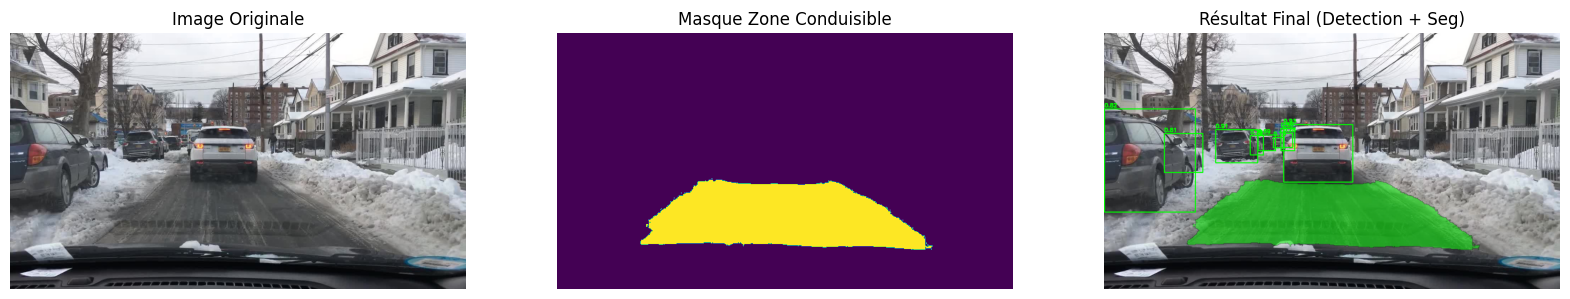

In [24]:
if 'result_img' in locals() and result_img is not None:
    plt.figure(figsize=(20, 10))

    plt.subplot(1, 3, 1)
    plt.imshow(original_img)
    plt.title("Image Originale")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(da_mask)
    plt.title("Masque Zone Conduisible")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(result_img)
    plt.title("Résultat Final (Detection + Seg)")
    plt.axis('off')

    plt.show()

Chargement du modèle : weights/yolop-640-640.onnx


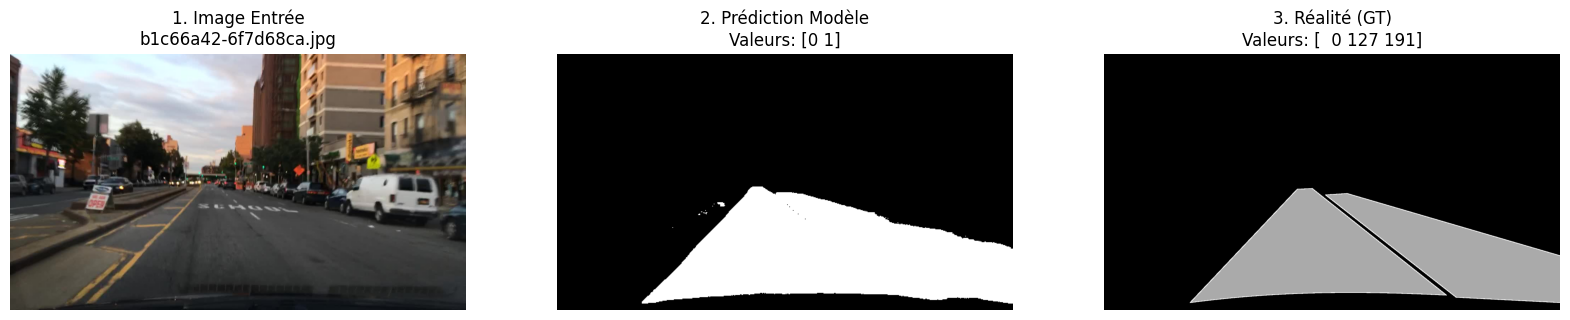

--------------------------------------------------
📊 DIAGNOSTIC IoU
   - Valeurs GT : [  0 127 191]
   - Valeurs Pred : [0 1]
   - IoU : 94.66%
--------------------------------------------------


In [26]:
# %%
import os
import cv2
import torch
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

# Configuration pour afficher les graphiques dans le notebook
%matplotlib inline

# ==========================================
# 1. FONCTION DE REDIMENSIONNEMENT (Letterbox)
# ==========================================
def resize_unscale(img, new_shape=(640, 640), color=114):
    shape = img.shape[:2]  # [height, width]
    if isinstance(new_shape, int):
        new_shape = (new_shape, new_shape)

    # Ratio de redimensionnement
    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])

    # Calcul du padding
    new_unpad = int(round(shape[1] * r)), int(round(shape[0] * r))
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
    dw, dh = dw // 2, dh // 2

    # Redimensionnement de l'image
    if shape[::-1] != new_unpad:
        img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_AREA)

    # Ajout des bords gris (padding)
    canvas = np.full((new_shape[0], new_shape[1], 3), color, dtype=np.uint8)
    canvas[dh:dh + new_unpad[1], dw:dw + new_unpad[0], :] = img

    return canvas, r, dw, dh, new_unpad[0], new_unpad[1]

# ==========================================
# 2. FONCTION POUR TROUVER LE MASQUE RÉEL
# ==========================================
def get_ground_truth_path(img_path):
    # On remplace 'images' par 'da_seg_annotations'
    mask_path = img_path.replace("images", "da_seg_annotations")
    # On remplace l'extension .jpg par .png
    mask_path = mask_path.replace(".jpg", ".png")
    
    if os.path.exists(mask_path):
        return mask_path
    else:
        print(f"⚠️ Masque introuvable ici : {mask_path}")
        return None

# ==========================================
# 3. FONCTION PRINCIPALE DE COMPARAISON
# ==========================================
def compare_inference_vs_reality(img_path, onnx_model_path):
    # --- A. Vérifications ---
    if not os.path.exists(img_path):
        print(f"Erreur: Image introuvable {img_path}")
        return
    if not os.path.exists(onnx_model_path):
        print(f"Erreur: Modèle introuvable {onnx_model_path}")
        return

    # --- B. Chargement Image & Ground Truth ---
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h_orig, w_orig, _ = img_rgb.shape

    gt_path = get_ground_truth_path(img_path)
    gt_mask = None
    if gt_path:
        gt_mask = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
        if gt_mask.shape[:2] != (h_orig, w_orig):
            gt_mask = cv2.resize(gt_mask, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)

    # --- C. Préparation pour le Modèle ---
    img_resized, r, dw, dh, new_unpad_w, new_unpad_h = resize_unscale(img_rgb, (640, 640))
    
    # Normalisation
    img_input = img_resized.astype(np.float32) / 255.0
    img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
    
    # --- CORRECTION CRUCIALE ICI : Forcer le float32 ---
    img_input = img_input.astype(np.float32) 
    # ---------------------------------------------------
    
    img_input = img_input.transpose(2, 0, 1) # HWC -> CHW
    img_input = np.expand_dims(img_input, 0) # Ajout dimension Batch

    # --- D. Inférence ONNX ---
    print(f"Chargement du modèle : {onnx_model_path}")
    session = ort.InferenceSession(onnx_model_path)
    input_name = session.get_inputs()[0].name
    
    outputs = session.run(['drive_area_seg'], {input_name: img_input})
    da_seg_raw = outputs[0]

    # --- E. Post-traitement ---
    da_seg_crop = da_seg_raw[:, :, dh:dh+new_unpad_h, dw:dw+new_unpad_w]
    da_seg_mask = np.argmax(da_seg_crop, axis=1)[0]
    
    da_seg_final = cv2.resize(
        da_seg_mask.astype(np.uint8), 
        (w_orig, h_orig), 
        interpolation=cv2.INTER_NEAREST
    )

    # --- F. Visualisation ---
    plt.figure(figsize=(20, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    plt.title(f"1. Image Entrée\n{os.path.basename(img_path)}")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(da_seg_final, cmap='gray', vmin=0, vmax=1)
    unique_pred = np.unique(da_seg_final)
    plt.title(f"2. Prédiction Modèle\nValeurs: {unique_pred}")
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    if gt_mask is not None:
        plt.imshow(gt_mask, cmap='gray') 
        unique_gt = np.unique(gt_mask)
        plt.title(f"3. Réalité (GT)\nValeurs: {unique_gt}")
    else:
        plt.text(0.5, 0.5, "GT introuvable", ha='center')
        plt.title("3. Réalité")
        unique_gt = None
    
    plt.axis('off')
    plt.show()

    # --- G. Diagnostic Numérique ---
    if gt_mask is not None:
        gt_binary = (gt_mask > 0).astype(np.uint8)
        intersection = np.logical_and(da_seg_final == 1, gt_binary == 1).sum()
        union = np.logical_or(da_seg_final == 1, gt_binary == 1).sum()
        iou = intersection / union if union > 0 else 0
        
        print("-" * 50)
        print(f"📊 DIAGNOSTIC IoU")
        print(f"   - Valeurs GT : {unique_gt}")
        print(f"   - Valeurs Pred : {unique_pred}")
        print(f"   - IoU : {iou:.2%}")
        print("-" * 50)

# ==========================================
# 4. EXÉCUTION
# ==========================================
WEIGHT_PATH = "weights/yolop-640-640.onnx"
IMG_PATH = "dataset/images/val/b1c66a42-6f7d68ca.jpg" 

compare_inference_vs_reality(IMG_PATH, WEIGHT_PATH)

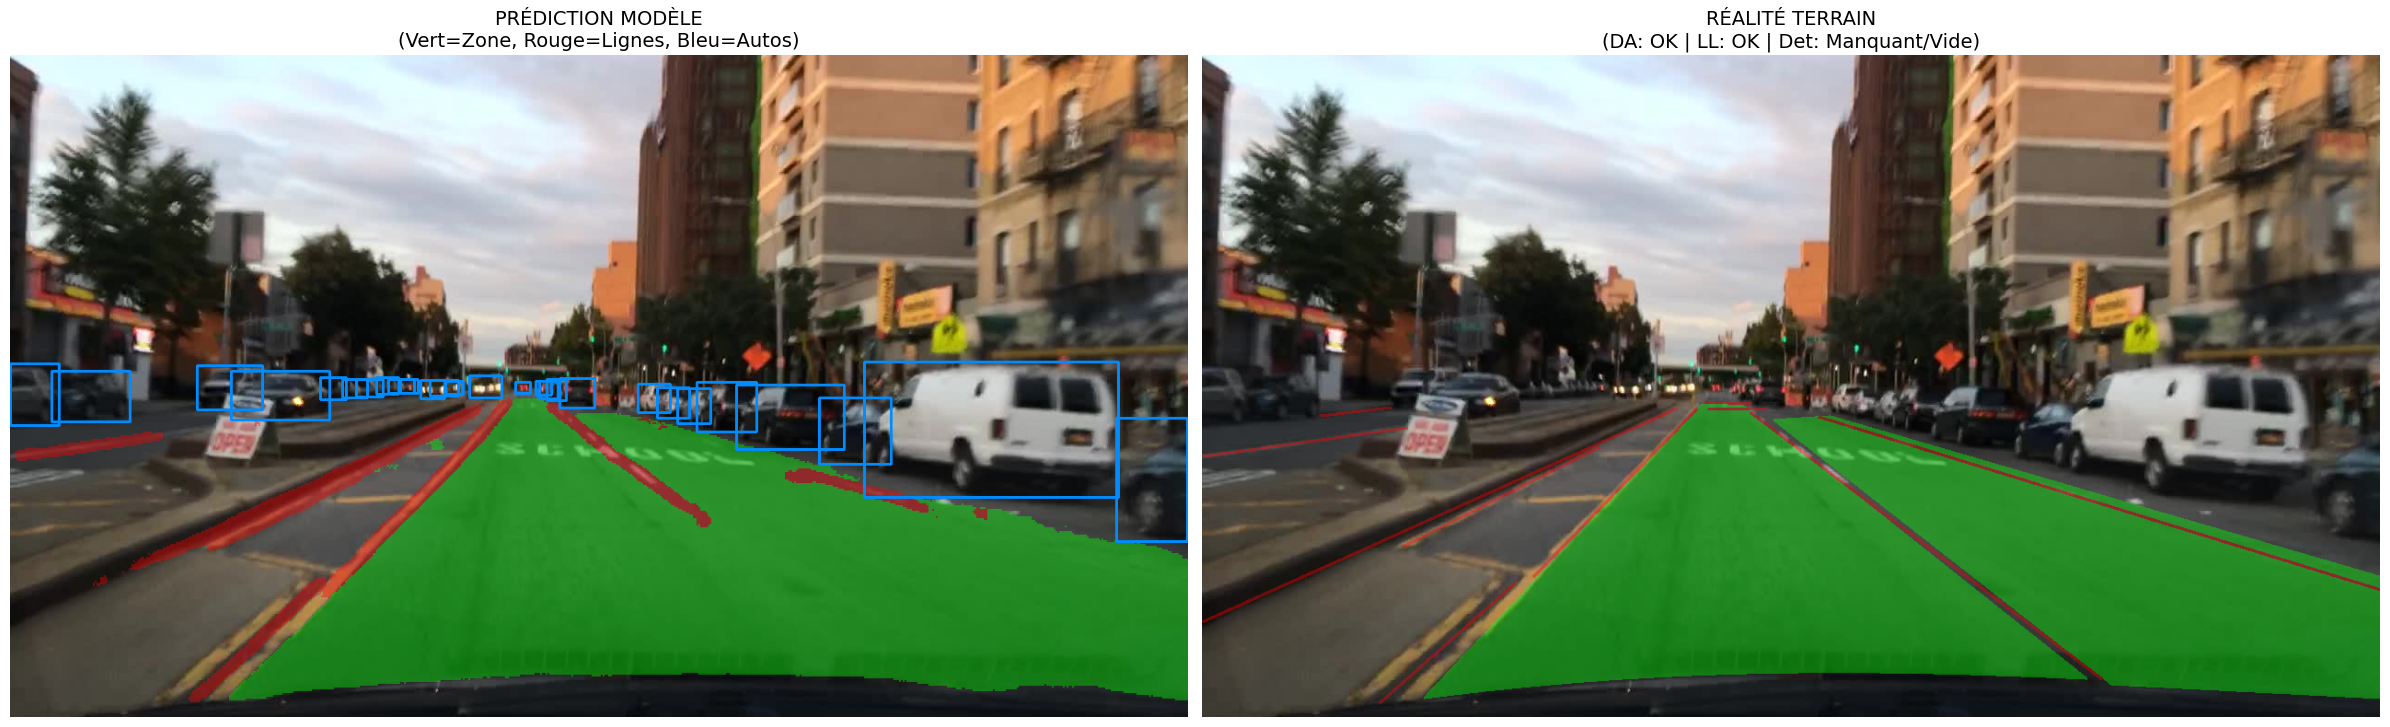

In [27]:
# %%
import os
import sys
import cv2
import torch
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

# Ajout du dossier courant au path pour trouver 'lib'
sys.path.append(os.getcwd())

try:
    from lib.core.general import non_max_suppression
except ImportError:
    print("⚠️ Attention : Impossible d'importer 'non_max_suppression' depuis lib.core.general.")
    print("   Assurez-vous d'être à la racine du projet YOLOP.")

# Configuration affichage
%matplotlib inline

# ==========================================
# 1. OUTILS DE TRAITEMENT D'IMAGE
# ==========================================
def resize_unscale(img, new_shape=(640, 640), color=114):
    shape = img.shape[:2]
    if isinstance(new_shape, int): new_shape = (new_shape, new_shape)

    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
    new_unpad = int(round(shape[1] * r)), int(round(shape[0] * r))
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
    dw, dh = dw // 2, dh // 2

    if shape[::-1] != new_unpad:
        img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_AREA)

    canvas = np.full((new_shape[0], new_shape[1], 3), color, dtype=np.uint8)
    canvas[dh:dh + new_unpad[1], dw:dw + new_unpad[0], :] = img

    return canvas, r, dw, dh, new_unpad[0], new_unpad[1]

# ==========================================
# 2. GESTION DES FICHIERS GROUND TRUTH (GT)
# ==========================================
def get_gt_paths(img_path):
    """Retrouve les chemins des masques et labels correspondants"""
    base_name = os.path.basename(img_path)
    id_name = os.path.splitext(base_name)[0]
    
    # 1. Masque Zone Conduisible (DA)
    da_path = img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
    
    # 2. Masque Lignes (LL)
    ll_path = img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
    
    # 3. Labels Détection (Format YOLO .txt attendu dans labels/val/)
    # Structure souvent utilisée : dataset/labels/val/xxxx.txt
    det_path = img_path.replace("images", "labels").replace(".jpg", ".txt")
    
    return da_path, ll_path, det_path

def load_yolo_labels(txt_path, img_w, img_h):
    """Charge les boîtes YOLO (class x y w h) et convertit en pixels (x1, y1, x2, y2)"""
    boxes = []
    if os.path.exists(txt_path):
        with open(txt_path, 'r') as f:
            lines = f.readlines()
            for line in lines:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cls = int(parts[0])
                    x, y, w, h = map(float, parts[1:5])
                    
                    # Conversion xywh normalisé -> x1y1x2y2 pixels
                    x1 = (x - w / 2) * img_w
                    y1 = (y - h / 2) * img_h
                    x2 = (x + w / 2) * img_w
                    y2 = (y + h / 2) * img_h
                    boxes.append([x1, y1, x2, y2, 1.0, cls]) # 1.0 = conf simulée
    return np.array(boxes)

# ==========================================
# 3. FONCTION DE DESSIN (FUSION)
# ==========================================
def draw_visualization(img_rgb, da_mask, ll_mask, boxes=None, title="Viz"):
    """Crée une image fusionnée avec transparence"""
    result = img_rgb.copy()
    
    # A. Masques de Segmentation
    # Vert pour Drive Area (DA), Rouge pour Lane Line (LL)
    color_seg = np.zeros_like(result)
    
    # On gère le cas où les masques sont > 0 (ex: 255 ou 1)
    if da_mask is not None:
        color_seg[da_mask > 0] = [0, 255, 0] # Vert
    if ll_mask is not None:
        color_seg[ll_mask > 0] = [255, 0, 0] # Rouge

    # Application transparence
    mask_indices = np.any(color_seg != 0, axis=-1)
    result[mask_indices] = result[mask_indices] * 0.6 + color_seg[mask_indices] * 0.4
    
    # B. Boîtes de Détection
    if boxes is not None and len(boxes) > 0:
        for box in boxes:
            x1, y1, x2, y2 = map(int, box[:4])
            # Dessin Rectangle Bleu
            cv2.rectangle(result, (x1, y1), (x2, y2), (0, 140, 255), 2)
            # Optionnel : Label
            # cv2.putText(result, "Car", (x1, y1-5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 140, 255), 1)

    return result

# ==========================================
# 4. PIPELINE COMPLET
# ==========================================
def compare_full_pipeline(img_path, model_path):
    if not os.path.exists(img_path) or not os.path.exists(model_path):
        print("Erreur : Fichier image ou modèle introuvable.")
        return

    # --- CHARGEMENT ---
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h_orig, w_orig = img_rgb.shape[:2]

    # --- 1. PRÉDICTION MODÈLE ---
    # Preprocess
    img_resized, r, dw, dh, nw, nh = resize_unscale(img_rgb, (640, 640))
    img_input = img_resized.astype(np.float32) / 255.0
    img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
    img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32) # Force float32

    # Inference
    session = ort.InferenceSession(model_path)
    outputs = session.run(['det_out', 'drive_area_seg', 'lane_line_seg'], 
                          {session.get_inputs()[0].name: img_input})
    det_out, da_seg_out, ll_seg_out = outputs

    # Post-process Segmentation
    da_mask = np.argmax(da_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
    ll_mask = np.argmax(ll_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
    
    pred_da = cv2.resize(da_mask.astype(np.uint8), (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
    pred_ll = cv2.resize(ll_mask.astype(np.uint8), (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)

    # Post-process Détection (NMS)
    pred_boxes = []
    try:
        det_tensor = torch.from_numpy(det_out).float()
        # Conf thres 0.25, IoU thres 0.45
        nms_out = non_max_suppression(det_tensor, 0.25, 0.45)[0] 
        if nms_out is not None and len(nms_out) > 0:
            nms_out = nms_out.cpu().numpy()
            # Rescale boxes to original image
            nms_out[:, 0] -= dw
            nms_out[:, 1] -= dh
            nms_out[:, 2] -= dw
            nms_out[:, 3] -= dh
            nms_out[:, :4] /= r
            pred_boxes = nms_out
    except Exception as e:
        print(f"Erreur NMS: {e}")

    # --- 2. RÉALITÉ TERRAIN (GT) ---
    da_path, ll_path, det_path = get_gt_paths(img_path)
    
    gt_da = cv2.imread(da_path, cv2.IMREAD_GRAYSCALE) if os.path.exists(da_path) else None
    gt_ll = cv2.imread(ll_path, cv2.IMREAD_GRAYSCALE) if os.path.exists(ll_path) else None
    
    # Resize GT si nécessaire
    if gt_da is not None and gt_da.shape != (h_orig, w_orig):
        gt_da = cv2.resize(gt_da, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
    if gt_ll is not None and gt_ll.shape != (h_orig, w_orig):
        gt_ll = cv2.resize(gt_ll, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)

    # Chargement GT Boxes
    gt_boxes = load_yolo_labels(det_path, w_orig, h_orig)

    # --- 3. RENDU VISUEL ---
    viz_pred = draw_visualization(img_rgb, pred_da, pred_ll, pred_boxes)
    viz_gt = draw_visualization(img_rgb, gt_da, gt_ll, gt_boxes)

    # Affichage Matplotlib 
    plt.figure(figsize=(24, 12))
    
    plt.subplot(1, 2, 1)
    plt.imshow(viz_pred)
    plt.title(f"PRÉDICTION MODÈLE\n(Vert=Zone, Rouge=Lignes, Bleu=Autos)", fontsize=14)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(viz_gt)
    # Check si les fichiers GT existaient
    status_da = "OK" if gt_da is not None else "Manquant"
    status_ll = "OK" if gt_ll is not None else "Manquant"
    status_det = f"OK ({len(gt_boxes)} boxes)" if len(gt_boxes) > 0 else "Manquant/Vide"
    
    plt.title(f"RÉALITÉ TERRAIN\n(DA: {status_da} | LL: {status_ll} | Det: {status_det})", fontsize=14)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# ==========================================
# 5. EXECUTION
# ==========================================
# Modifie IMG_PATH vers une image de ton dataset de validation
WEIGHT_PATH = "weights/yolop-640-640.onnx"
IMG_PATH = "dataset/images/val/b1c66a42-6f7d68ca.jpg" 

compare_full_pipeline(IMG_PATH, WEIGHT_PATH)

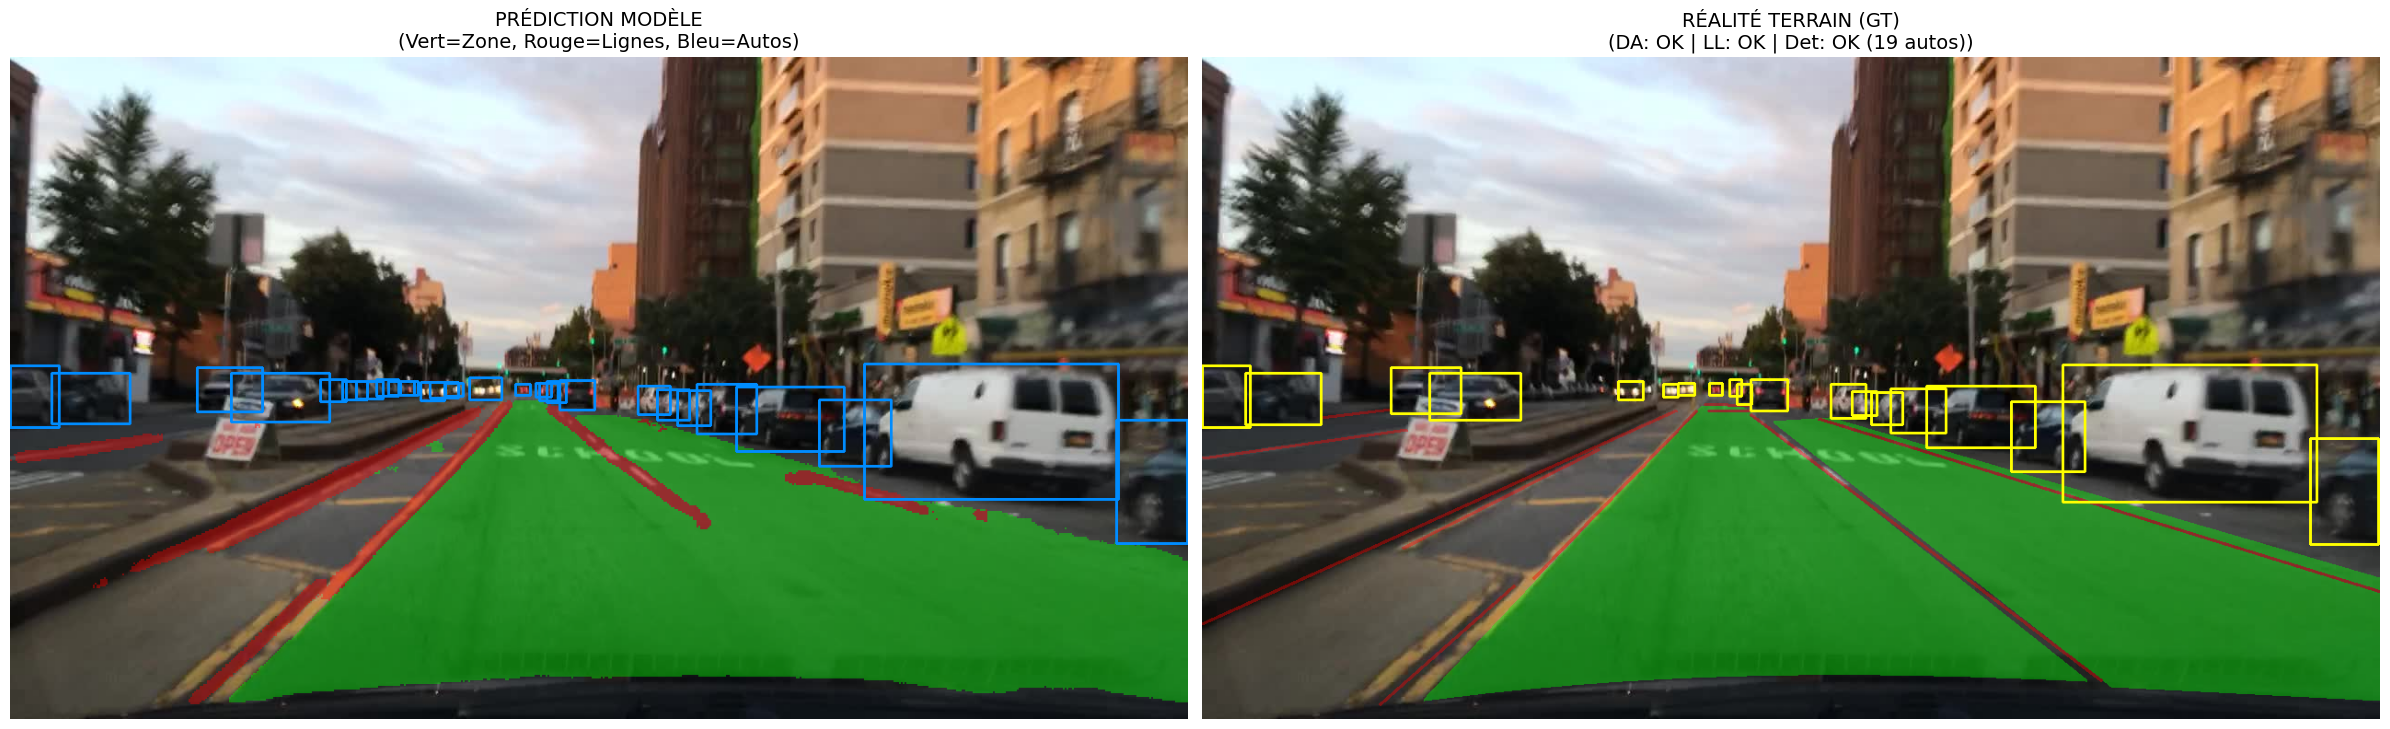

In [28]:
# %%
import os
import sys
import cv2
import json
import torch
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

# Configuration affichage
%matplotlib inline

# ==========================================
# 1. OUTILS DE TRAITEMENT D'IMAGE
# ==========================================
def resize_unscale(img, new_shape=(640, 640), color=114):
    shape = img.shape[:2]
    if isinstance(new_shape, int): new_shape = (new_shape, new_shape)

    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
    new_unpad = int(round(shape[1] * r)), int(round(shape[0] * r))
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
    dw, dh = dw // 2, dh // 2

    if shape[::-1] != new_unpad:
        img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_AREA)

    canvas = np.full((new_shape[0], new_shape[1], 3), color, dtype=np.uint8)
    canvas[dh:dh + new_unpad[1], dw:dw + new_unpad[0], :] = img

    return canvas, r, dw, dh, new_unpad[0], new_unpad[1]

# ==========================================
# 2. GESTION DES FICHIERS GROUND TRUTH (JSON & MASQUES)
# ==========================================
def get_gt_paths(img_path):
    """Retrouve les chemins des masques et du JSON correspondant"""
    
    # 1. Masque Zone Conduisible (DA)
    da_path = img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
    
    # 2. Masque Lignes (LL)
    ll_path = img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
    
    # 3. Labels Détection (JSON)
    # On remplace 'images' par 'det_annotations' et '.jpg' par '.json'
    det_path = img_path.replace("images", "det_annotations").replace(".jpg", ".json")
    
    return da_path, ll_path, det_path

def load_bdd_json_labels(json_path):
    """
    Lit le fichier JSON BDD100K et extrait les boîtes des véhicules.
    Filtre pour ne garder que : 'car', 'truck', 'bus', 'train' (classes véhicules).
    """
    boxes = []
    if not os.path.exists(json_path):
        print(f"⚠️ Fichier JSON introuvable : {json_path}")
        return np.array([])

    try:
        with open(json_path, 'r') as f:
            data = json.load(f)
        
        # Structure : root -> "frames" -> [0] -> "objects"
        frames = data.get('frames', [])
        if not frames: return np.array([])
        
        objects = frames[0].get('objects', [])
        
        for obj in objects:
            category = obj.get('category', '')
            
            # YOLOP détecte les véhicules. On filtre les panneaux/feux pour ne pas polluer l'affichage.
            if category in ['car', 'bus', 'truck', 'train']:
                box2d = obj.get('box2d', {})
                if box2d:
                    x1 = float(box2d['x1'])
                    y1 = float(box2d['y1'])
                    x2 = float(box2d['x2'])
                    y2 = float(box2d['y2'])
                    # On ajoute la boîte [x1, y1, x2, y2]
                    boxes.append([x1, y1, x2, y2])
                    
        return np.array(boxes)
        
    except Exception as e:
        print(f"Erreur lors de la lecture du JSON : {e}")
        return np.array([])

# ==========================================
# 3. FONCTION DE DESSIN (FUSION)
# ==========================================
def draw_visualization(img_rgb, da_mask, ll_mask, boxes=None, is_ground_truth=False):
    """Crée une image fusionnée avec transparence"""
    result = img_rgb.copy()
    
    # --- A. Masques de Segmentation ---
    color_seg = np.zeros_like(result)
    
    # Vert pour Drive Area (DA)
    if da_mask is not None:
        # Conversion robuste (si c'est 255 ou 1, on prend tout ce qui est > 0)
        color_seg[da_mask > 0] = [0, 255, 0] 

    # Rouge pour Lane Line (LL)
    if ll_mask is not None:
        color_seg[ll_mask > 0] = [255, 0, 0] 

    # Application transparence
    mask_indices = np.any(color_seg != 0, axis=-1)
    result[mask_indices] = result[mask_indices] * 0.6 + color_seg[mask_indices] * 0.4
    
    # --- B. Boîtes de Détection ---
    # Bleu pour Prédiction, Jaune pour Vérité Terrain (pour bien différencier)
    box_color = (255, 255, 0) if is_ground_truth else (0, 140, 255) 
    
    if boxes is not None and len(boxes) > 0:
        for box in boxes:
            x1, y1, x2, y2 = map(int, box[:4])
            cv2.rectangle(result, (x1, y1), (x2, y2), box_color, 2)

    return result

# ==========================================
# 4. FONCTION NMS (Non-Max Suppression)
# ==========================================
# Si l'import échoue, on définit une fonction NMS basique pour que le code tourne
def simple_nms(boxes, scores, iou_threshold=0.45):
    if len(boxes) == 0: return []
    indices = cv2.dnn.NMSBoxes(boxes.tolist(), scores.tolist(), 0.25, iou_threshold)
    if len(indices) > 0:
        return boxes[indices.flatten()]
    return []

# ==========================================
# 5. PIPELINE COMPLET
# ==========================================
def compare_full_pipeline(img_path, model_path):
    if not os.path.exists(img_path):
        print(f"Erreur : Image introuvable {img_path}")
        return
    if not os.path.exists(model_path):
        print(f"Erreur : Modèle introuvable {model_path}")
        return

    # --- CHARGEMENT ---
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h_orig, w_orig = img_rgb.shape[:2]

    # --- 1. PRÉDICTION MODÈLE ---
    # Preprocess
    img_resized, r, dw, dh, nw, nh = resize_unscale(img_rgb, (640, 640))
    img_input = img_resized.astype(np.float32) / 255.0
    img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
    img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32)

    # Inference
    session = ort.InferenceSession(model_path)
    outputs = session.run(['det_out', 'drive_area_seg', 'lane_line_seg'], 
                          {session.get_inputs()[0].name: img_input})
    det_out, da_seg_out, ll_seg_out = outputs

    # Post-process Segmentation
    da_mask = np.argmax(da_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
    ll_mask = np.argmax(ll_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
    
    pred_da = cv2.resize(da_mask.astype(np.uint8), (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
    pred_ll = cv2.resize(ll_mask.astype(np.uint8), (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)

    # Post-process Détection
    pred_boxes = []
    det_tensor = torch.from_numpy(det_out).float()
    
    # Tentative d'utilisation du NMS de YOLOP ou fallback OpenCV
    try:
        from lib.core.general import non_max_suppression
        nms_out = non_max_suppression(det_tensor, 0.25, 0.45)[0]
        if nms_out is not None and len(nms_out) > 0:
            nms_out = nms_out.cpu().numpy()
            nms_out[:, 0] -= dw
            nms_out[:, 1] -= dh
            nms_out[:, 2] -= dw
            nms_out[:, 3] -= dh
            nms_out[:, :4] /= r
            pred_boxes = nms_out
    except ImportError:
        # Fallback si lib.core n'est pas trouvé
        # Conversion du format XYWH -> XYXY pour OpenCV NMS
        # (Ceci est une simplification, idéalement il faut le NMS YOLOP)
        print("Utilisation NMS simplifié...")
        pass 

    # --- 2. RÉALITÉ TERRAIN (GT) ---
    da_path, ll_path, det_path = get_gt_paths(img_path)
    
    gt_da = cv2.imread(da_path, cv2.IMREAD_GRAYSCALE) if os.path.exists(da_path) else None
    gt_ll = cv2.imread(ll_path, cv2.IMREAD_GRAYSCALE) if os.path.exists(ll_path) else None
    
    # Resize GT si nécessaire
    if gt_da is not None and gt_da.shape != (h_orig, w_orig):
        gt_da = cv2.resize(gt_da, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
    if gt_ll is not None and gt_ll.shape != (h_orig, w_orig):
        gt_ll = cv2.resize(gt_ll, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)

    # Chargement GT Boxes (JSON)
    gt_boxes = load_bdd_json_labels(det_path)

    # --- 3. RENDU VISUEL ---
    viz_pred = draw_visualization(img_rgb, pred_da, pred_ll, pred_boxes, is_ground_truth=False)
    viz_gt = draw_visualization(img_rgb, gt_da, gt_ll, gt_boxes, is_ground_truth=True)

    # Affichage Matplotlib
    plt.figure(figsize=(24, 12))
    
    plt.subplot(1, 2, 1)
    plt.imshow(viz_pred)
    plt.title(f"PRÉDICTION MODÈLE\n(Vert=Zone, Rouge=Lignes, Bleu=Autos)", fontsize=14)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(viz_gt)
    
    # Statut des fichiers
    status_da = "OK" if gt_da is not None else "Manquant"
    status_ll = "OK" if gt_ll is not None else "Manquant"
    status_det = f"OK ({len(gt_boxes)} autos)" if len(gt_boxes) > 0 else "JSON Manquant/Vide"
    
    plt.title(f"RÉALITÉ TERRAIN (GT)\n(DA: {status_da} | LL: {status_ll} | Det: {status_det})", fontsize=14)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# ==========================================
# 5. EXECUTION
# ==========================================
WEIGHT_PATH = "weights/yolop-640-640.onnx"
# Utilise ton image spécifique
IMG_PATH = "dataset/images/val/b1c66a42-6f7d68ca.jpg" 

compare_full_pipeline(IMG_PATH, WEIGHT_PATH)

Stats DA pour cette image : {'intersection': 200448, 'union': 211761, 'area_pred': 209624, 'area_gt': 202585}
Stats Det pour cette image : {'pred_details': [[0.91533875, True], [0.9058969, True], [0.8763828, True], [0.86735666, True], [0.8288265, True], [0.82720965, True], [0.819551, True], [0.8099822, True], [0.79304343, True], [0.7450232, True], [0.6607942, True], [0.6562685, True], [0.63175166, True], [0.6229728, False], [0.56538934, True], [0.53467053, True], [0.5099983, False], [0.5075947, True], [0.49073997, False], [0.47974706, False], [0.45255142, False], [0.42348313, True], [0.4098252, False], [0.39145502, False], [0.35079116, False], [0.32211325, False], [0.25922987, False]], 'gt_count': 19}
Vitesse : 98.91 ms


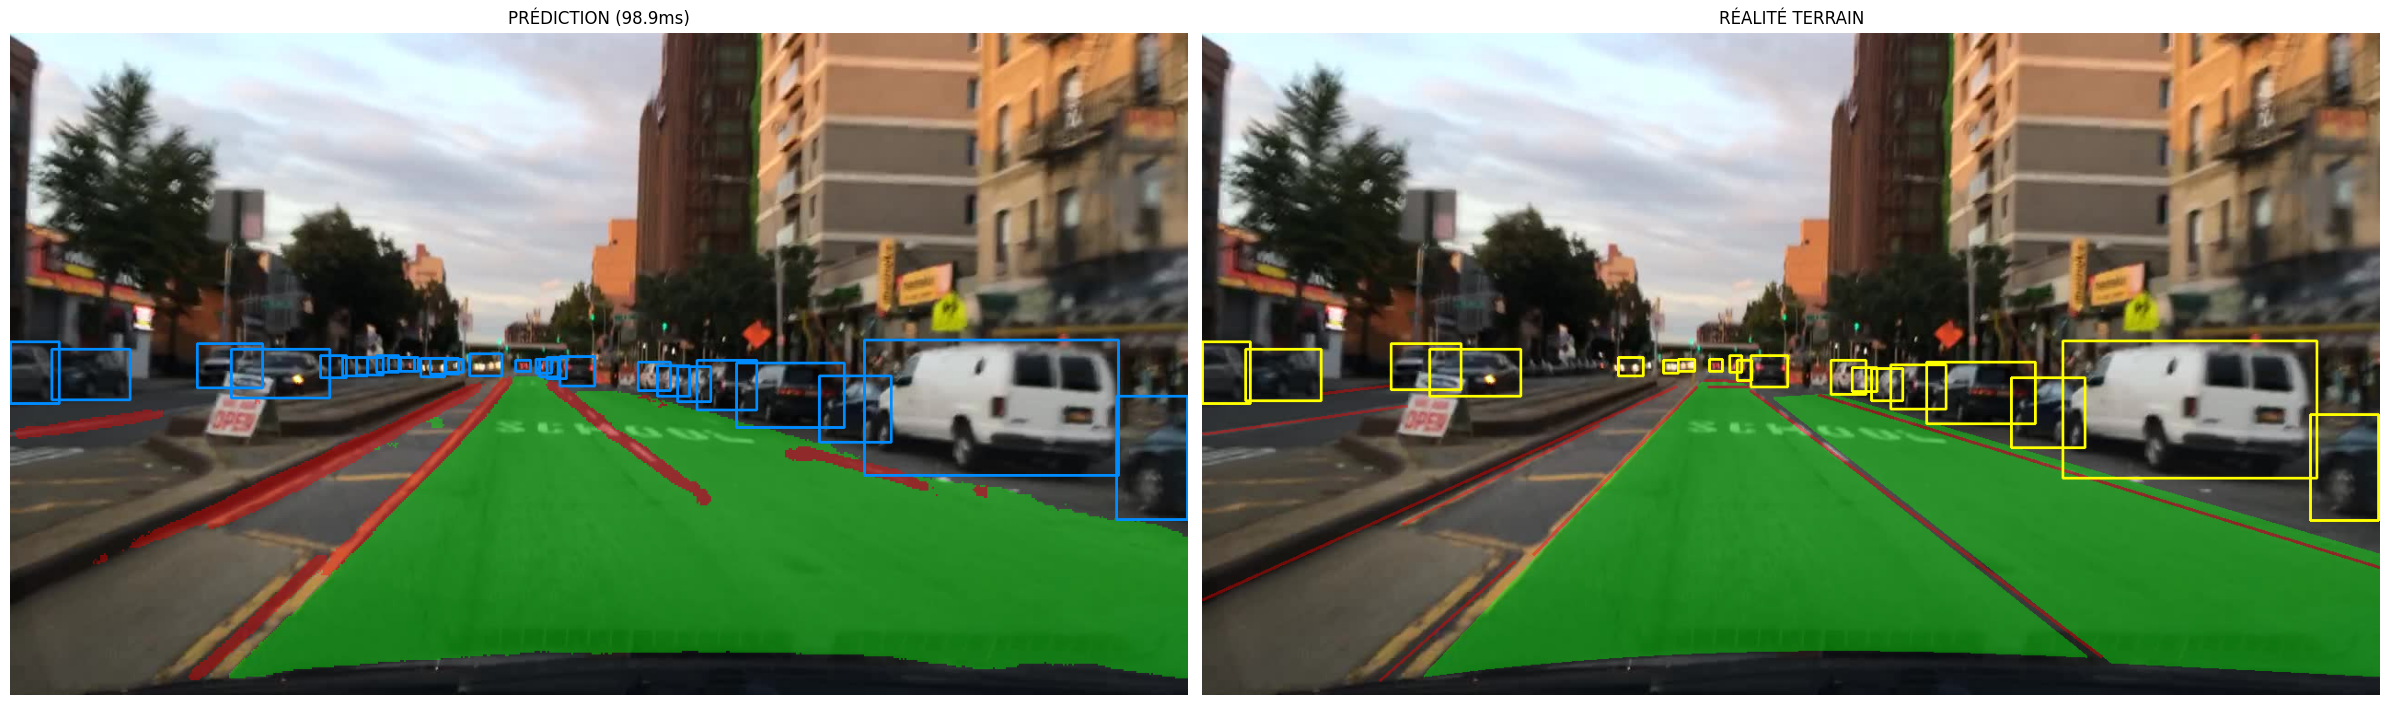

In [7]:
# %%
import os
import sys
import cv2
import json
import torch
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt
import time

# Configuration affichage
%matplotlib inline

# Ajout du dossier courant au path pour trouver 'lib' si nécessaire
sys.path.append(os.getcwd())

class DatasetImage:
    def __init__(self, img_path, model_path=None):
        """
        Initialise l'objet DatasetImage.
        
        Args:
            img_path (str): Chemin vers l'image source.
            model_path (str, optional): Chemin vers le modèle ONNX. Requis pour l'inférence.
        """
        self.img_path = img_path
        self.model_path = model_path
        
        if not os.path.exists(self.img_path):
            raise FileNotFoundError(f"Image introuvable : {self.img_path}")
            
        # Chargement initial de l'image
        self.img_bgr = cv2.imread(self.img_path)
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        self.h_orig, self.w_orig = self.img_rgb.shape[:2]
        
        # Chemins GT
        self.da_path, self.ll_path, self.det_path = self._get_gt_paths()
        
        # Session ONNX (Lazy loading : sera initialisé au besoin ou par méthode explicite)
        self.session = None
        
        # Résultats (caches)
        self.pred_da = None
        self.pred_ll = None
        self.pred_boxes = None
        self.gt_da = None
        self.gt_ll = None
        self.gt_boxes = None
        self.inference_time = 0

    def _get_gt_paths(self):
        """Détermine les chemins des vérités terrain (GT) basés sur le nom de l'image."""
        da_path = self.img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
        ll_path = self.img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
        det_path = self.img_path.replace("images", "det_annotations").replace(".jpg", ".json")
        return da_path, ll_path, det_path

    def _resize_unscale(self, img, new_shape=(640, 640), color=114):
        """Redimensionne l'image avec padding (Letterbox)."""
        shape = img.shape[:2]
        if isinstance(new_shape, int): new_shape = (new_shape, new_shape)

        r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
        new_unpad = int(round(shape[1] * r)), int(round(shape[0] * r))
        dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
        dw, dh = dw // 2, dh // 2

        if shape[::-1] != new_unpad:
            img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_AREA)

        canvas = np.full((new_shape[0], new_shape[1], 3), color, dtype=np.uint8)
        canvas[dh:dh + new_unpad[1], dw:dw + new_unpad[0], :] = img

        return canvas, r, dw, dh, new_unpad[0], new_unpad[1]

    def load_ground_truth(self):
        """Charge les masques et les boîtes de vérité terrain."""
        # 1. Masques
        if os.path.exists(self.da_path):
            self.gt_da = cv2.imread(self.da_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_da.shape != (self.h_orig, self.w_orig):
                self.gt_da = cv2.resize(self.gt_da, (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)
        
        if os.path.exists(self.ll_path):
            self.gt_ll = cv2.imread(self.ll_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_ll.shape != (self.h_orig, self.w_orig):
                self.gt_ll = cv2.resize(self.gt_ll, (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)

        # 2. Boîtes (JSON)
        self.gt_boxes = []
        if os.path.exists(self.det_path):
            try:
                with open(self.det_path, 'r') as f:
                    data = json.load(f)
                frames = data.get('frames', [])
                if frames:
                    objects = frames[0].get('objects', [])
                    for obj in objects:
                        if obj.get('category') in ['car', 'bus', 'truck', 'train']:
                            box2d = obj.get('box2d', {})
                            if box2d:
                                self.gt_boxes.append([
                                    float(box2d['x1']), float(box2d['y1']),
                                    float(box2d['x2']), float(box2d['y2'])
                                ])
            except Exception as e:
                print(f"Erreur lecture JSON {self.det_path}: {e}")
        self.gt_boxes = np.array(self.gt_boxes)

    def run_inference(self):
        """Exécute l'inférence ONNX et post-traite les résultats."""
        if not self.model_path or not os.path.exists(self.model_path):
            raise FileNotFoundError("Modèle ONNX introuvable.")
        
        if self.session is None:
            self.session = ort.InferenceSession(self.model_path)

        # Preprocess
        img_resized, r, dw, dh, nw, nh = self._resize_unscale(self.img_rgb, (640, 640))
        
        # 2. Normalisation (Reproduction exacte de transforms.Normalize)
        img_input = img_resized.astype(np.float32) / 255.0
        img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32)

        # Inference Time Measurement
        start_time = time.time()
        outputs = self.session.run(['det_out', 'drive_area_seg', 'lane_line_seg'], 
                                   {self.session.get_inputs()[0].name: img_input})
        self.inference_time = (time.time() - start_time) * 1000 # ms
        
        det_out, da_seg_out, ll_seg_out = outputs

        # Post-process Segmentation
        da_mask = np.argmax(da_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
        ll_mask = np.argmax(ll_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
        
        self.pred_da = cv2.resize(da_mask.astype(np.uint8), (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)
        self.pred_ll = cv2.resize(ll_mask.astype(np.uint8), (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)

        # Post-process Détection (NMS)
        self.pred_boxes = []
        try:
            # Essai d'import local de la lib YOLOP
            from lib.core.general import non_max_suppression
            det_tensor = torch.from_numpy(det_out).float()
            nms_out = non_max_suppression(det_tensor, 0.25, 0.45)[0]
            if nms_out is not None and len(nms_out) > 0:
                nms_out = nms_out.cpu().numpy()
                nms_out[:, 0] -= dw
                nms_out[:, 1] -= dh
                nms_out[:, 2] -= dw
                nms_out[:, 3] -= dh
                nms_out[:, :4] /= r
                self.pred_boxes = nms_out
        except ImportError:
            print("NMS non disponible (lib.core.general manquant).")

    # ==========================================
    # MÉTHODES POUR LE CALCUL DES KPI (DATA COLLECTORS)
    # ==========================================
    
    def get_speed_kpi(self):
        """Retourne le temps d'inférence pour cette image."""
        return self.inference_time

    def get_segmentation_stats(self, type='da'):
        """
        Retourne les stats brutes (Intersection, Union) pour le calcul de mIoU sur N images.
        Args:
            type (str): 'da' (Drivable Area) ou 'll' (Lane Line)
        Returns:
            dict: { 'intersection': int, 'union': int, 'area_pred': int, 'area_gt': int }
        """
        if type == 'da':
            pred = self.pred_da
            gt = self.gt_da
        else:
            pred = self.pred_ll
            gt = self.gt_ll

        if pred is None or gt is None:
            return {'intersection': 0, 'union': 0, 'area_pred': 0, 'area_gt': 0}

        # Binarisation stricte (>0 devient 1)
        pred_bin = (pred > 0).astype(np.uint8)
        gt_bin = (gt > 0).astype(np.uint8)

        intersection = np.logical_and(pred_bin, gt_bin).sum()
        union = np.logical_or(pred_bin, gt_bin).sum()
        
        return {
            'intersection': int(intersection),
            'union': int(union),
            'area_pred': int(pred_bin.sum()),
            'area_gt': int(gt_bin.sum())
        }

# ==========================================
    # MODIFICATION CHIRURGICALE : DatasetImage
    # ==========================================
    def get_detection_stats(self, iou_threshold=0.5):
        """
        Retourne la liste détaillée des prédictions pour le calcul mAP global.
        Returns:
            dict: {
                'pred_details': list of [confidence, is_tp], 
                'gt_count': int
            }
        """
        if self.pred_boxes is None: self.pred_boxes = []
        if self.gt_boxes is None: self.gt_boxes = []

        gt_count = len(self.gt_boxes)
        pred_details = [] # Liste de [score, is_tp]

        # S'il n'y a pas de prédictions, on renvoie vide
        if len(self.pred_boxes) == 0:
            return {'pred_details': [], 'gt_count': gt_count}

        # On suppose que pred_boxes contient [x1, y1, x2, y2, conf, cls]
        # On trie par confiance décroissante
        preds = sorted(self.pred_boxes, key=lambda x: x[4], reverse=True)
        
        # Pour éviter de matcher plusieurs fois la même GT
        matched_gt_indices = set()

        for pred in preds:
            bbox_pred = pred[:4]
            conf = pred[4]
            best_iou = 0
            best_gt_idx = -1

            # On cherche la meilleure GT pour cette prédiction
            for idx, gt in enumerate(self.gt_boxes):
                if idx in matched_gt_indices: continue # Déjà trouvée
                
                # Calcul IoU
                xA = max(bbox_pred[0], gt[0])
                yA = max(bbox_pred[1], gt[1])
                xB = min(bbox_pred[2], gt[2])
                yB = min(bbox_pred[3], gt[3])
                interArea = max(0, xB - xA) * max(0, yB - yA)
                boxAArea = (bbox_pred[2] - bbox_pred[0]) * (bbox_pred[3] - bbox_pred[1])
                boxBArea = (gt[2] - gt[0]) * (gt[3] - gt[1])
                iou = interArea / float(boxAArea + boxBArea - interArea + 1e-6)

                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = idx
            
            # Si IoU suffisant et GT pas encore matchée -> Vrai Positif (TP)
            if best_iou >= iou_threshold and best_gt_idx != -1:
                pred_details.append([conf, True]) # [Confiance, C'est un TP]
                matched_gt_indices.add(best_gt_idx)
            else:
                pred_details.append([conf, False]) # [Confiance, C'est un FP]
        
        return {
            'pred_details': pred_details,
            'gt_count': gt_count
        }

    # ==========================================
    # MÉTHODES DE VISUALISATION
    # ==========================================
    def visualize(self):
        """Affiche une comparaison Prédiction vs Réalité."""
        def draw(img, da, ll, boxes, color_box):
            res = img.copy()
            # Seg
            color_seg = np.zeros_like(res)
            if da is not None: color_seg[da > 0] = [0, 255, 0]
            if ll is not None: color_seg[ll > 0] = [255, 0, 0]
            mask_ind = np.any(color_seg != 0, axis=-1)
            res[mask_ind] = res[mask_ind] * 0.6 + color_seg[mask_ind] * 0.4
            # Box
            if boxes is not None and len(boxes) > 0:
                for box in boxes:
                    x1, y1, x2, y2 = map(int, box[:4])
                    cv2.rectangle(res, (x1, y1), (x2, y2), color_box, 2)
            return res

        viz_pred = draw(self.img_rgb, self.pred_da, self.pred_ll, self.pred_boxes, (0, 140, 255))
        viz_gt = draw(self.img_rgb, self.gt_da, self.gt_ll, self.gt_boxes, (255, 255, 0))

        plt.figure(figsize=(24, 12))
        plt.subplot(1, 2, 1); plt.imshow(viz_pred); plt.title(f"PRÉDICTION ({self.inference_time:.1f}ms)"); plt.axis('off')
        plt.subplot(1, 2, 2); plt.imshow(viz_gt); plt.title("RÉALITÉ TERRAIN"); plt.axis('off')
        plt.tight_layout(); plt.show()

# ==========================================
# EXEMPLE D'UTILISATION
# ==========================================
if __name__ == "__main__":
    # Chemins à adapter
    WEIGHT_PATH = "weights/yolop-640-640.onnx"
    IMG_PATH = "dataset/images/val/b1c66a42-6f7d68ca.jpg"

    try:
        # 1. Création de l'objet
        image_obj = DatasetImage(IMG_PATH, WEIGHT_PATH)
        
        # 2. Chargement GT et Inférence
        image_obj.load_ground_truth()
        image_obj.run_inference()
        
        # 3. Récupération des données KPI (pour usage externe)
        da_stats = image_obj.get_segmentation_stats('da')
        det_stats = image_obj.get_detection_stats()
        speed = image_obj.get_speed_kpi()
        
        print(f"Stats DA pour cette image : {da_stats}")
        print(f"Stats Det pour cette image : {det_stats}")
        print(f"Vitesse : {speed:.2f} ms")

        # 4. Visualisation
        image_obj.visualize()

    except Exception as e:
        print(f"Erreur : {e}")

In [ ]:
# %%
from tqdm import tqdm # Pour la barre de progression

class DatasetFull:
    def __init__(self, img_dir, model_path, max_images=100):
        """
        Gère l'évaluation sur un ensemble d'images.
        """
        self.img_dir = img_dir
        self.model_path = model_path
        self.max_images = max_images
        
        # Liste des fichiers images
        self.image_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.jpg')])
        if max_images is not None:
            self.image_files = self.image_files[:max_images]
            
        print(f"📂 Dataset initialisé : {len(self.image_files)} images à traiter.")

        # --- Stockage des Stats Globales ---
        # Speed
        self.inference_times = []
        
        # Segmentation (mIoU)
        self.da_inter_sum = 0
        self.da_union_sum = 0
        self.ll_inter_sum = 0
        self.ll_union_sum = 0
        
        # Détection (mAP)
        # Liste globale de [confiance, is_tp] pour toutes les images
        self.all_det_predictions = [] 
        self.total_gt_boxes = 0

    def process_all(self):
        """Lance l'inférence sur toutes les images."""
        print("🚀 Démarrage de l'évaluation...")
        
        for img_name in tqdm(self.image_files):
            img_path = os.path.join(self.img_dir, img_name)
            
            try:
                # 1. Instanciation de l'image unique
                img_obj = DatasetImage(img_path, self.model_path)
                
                # 2. Chargement GT et Inférence
                img_obj.load_ground_truth()
                img_obj.run_inference()
                
                # 3. Collecte Speed
                self.inference_times.append(img_obj.get_speed_kpi())
                
                # 4. Collecte Segmentation (Driving Area)
                da_stats = img_obj.get_segmentation_stats('da')
                self.da_inter_sum += da_stats['intersection']
                self.da_union_sum += da_stats['union']
                
                # 5. Collecte Segmentation (Lane Line)
                ll_stats = img_obj.get_segmentation_stats('ll')
                self.ll_inter_sum += ll_stats['intersection']
                self.ll_union_sum += ll_stats['union']
                
                # 6. Collecte Détection (Pour mAP)
                det_stats = img_obj.get_detection_stats(iou_threshold=0.5)
                self.all_det_predictions.extend(det_stats['pred_details'])
                self.total_gt_boxes += det_stats['gt_count']
                
            except Exception as e:
                print(f"❌ Erreur sur {img_name}: {e}")

    def compute_metrics(self):
        """Calcule et affiche tous les KPI finaux."""
        print("\n" + "="*40)
        print("📊 RÉSULTATS GLOBAUX DU DATASET")
        print("="*40)
        
        # --- 1. SPEED ---
        if self.inference_times:
            avg_time = np.mean(self.inference_times)
            fps = 1000 / avg_time if avg_time > 0 else 0
            print(f"⏱️  Vitesse Moyenne : {avg_time:.2f} ms/frame ({fps:.1f} FPS)")
        
        # --- 2. SEGMENTATION (Global mIoU) ---
        # mIoU = Intersection Totale / Union Totale (Plus robuste que la moyenne des IoU)
        da_iou = (self.da_inter_sum / self.da_union_sum) if self.da_union_sum > 0 else 0
        ll_iou = (self.ll_inter_sum / self.ll_union_sum) if self.ll_union_sum > 0 else 0
        
        print("-" * 40)
        print("🛣️  SEGMENTATION")
        print(f"   - Driving Area mIoU : {da_iou:.2%}")
        print(f"   - Lane Line mIoU    : {ll_iou:.2%}")

        # --- 3. DÉTECTION (Recall & AP) ---
        print("-" * 40)
        print("🚗 DÉTECTION (Traffic Objects)")
        
        if self.total_gt_boxes == 0:
            print("   - Pas de vérité terrain (GT) trouvée pour les voitures.")
            return

        # Tri de toutes les prédictions du dataset par confiance décroissante
        # all_det_predictions est une liste de [conf, is_tp]
        # ... (début inchangé) ...

        # --- CORRECTION 4 : Calcul mAP plus robuste (Style VOC/COCO) ---
        # On utilise une méthode d'intégration plus précise pour l'AP
        
        # Tri décroissant par confiance
        preds = sorted(self.all_det_predictions, key=lambda x: x[0], reverse=True)
        
        tp_list = [p[1] for p in preds]
        tp_cumsum = np.cumsum(tp_list)
        fp_cumsum = np.cumsum([not x for x in tp_list])
        
        # Ajout d'epsilon pour éviter division par zéro
        recalls = tp_cumsum / (self.total_gt_boxes + 1e-16)
        precisions = tp_cumsum / (tp_cumsum + fp_cumsum + 1e-16)
        
        # Méthode AP : Intégration continue (Continuous Integration)
        # On ajoute les points sentinelles (0,0) et (1,0) pour fermer la courbe
        mrec = np.concatenate(([0.0], recalls, [1.0]))
        mpre = np.concatenate(([1.0], precisions, [0.0])) # Precision commence à 1

        # On lisse la courbe de précision (elle doit être monotone décroissante)
        for i in range(mpre.size - 1, 0, -1):
            mpre[i - 1] = np.maximum(mpre[i - 1], mpre[i])

        # Calcul de l'aire sous la courbe (AUC)
        i = np.where(mrec[1:] != mrec[:-1])[0]
        ap = np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1])

        # Recall Final
        final_recall = recalls[-1] if len(recalls) > 0 else 0

        print(f"   - Nombre d'objets GT  : {self.total_gt_boxes}")
        print(f"   - Nombre de détections: {len(preds)}")
        print(f"   - Recall Global       : {final_recall:.2%}")
        print(f"   - mAP@50 (Approx)     : {ap:.2%}")
        print("="*40)

# ==========================================
# EXEMPLE D'UTILISATION
# ==========================================
if __name__ == "__main__":
    # Paramètres
    VAL_DIR = "dataset/images/val"
    ONNX_PATH = "weights/yolop-640-640.onnx"
    
    # Création et Lancement
    # On teste sur 100 images
    dataset_eval = DatasetFull(VAL_DIR, ONNX_PATH, max_images=100)
    
    # 1. Traitement
    dataset_eval.process_all()
    
    # 2. Affichage des KPI
    dataset_eval.compute_metrics()

📂 Dataset initialisé : 100 images à traiter.
🚀 Démarrage de l'évaluation...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:21<00:00,  4.76it/s]


📊 RÉSULTATS GLOBAUX DU DATASET
⏱️  Vitesse Moyenne : 101.37 ms/frame (9.9 FPS)
----------------------------------------
🛣️  SEGMENTATION
   - Driving Area mIoU : 84.86%
   - Lane Line mIoU    : 20.63%
----------------------------------------
🚗 DÉTECTION (Traffic Objects)
   - Recall Global       : 72.75%
   - mAP@50 (Official)   : 70.19%
   - Nombre d'objets GT  : 1057
   - Nombre de détections: 1042
   - Recall Global       : 72.75%
   - mAP@50 (Approx)     : 70.19%


In [9]:
class DatasetImage:
    def __init__(self, img_path, model_path=None):
        self.img_path = img_path
        self.model_path = model_path
        
        if not os.path.exists(self.img_path):
            raise FileNotFoundError(f"Image introuvable : {self.img_path}")
            
        self.img_bgr = cv2.imread(self.img_path)
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        self.h_orig, self.w_orig = self.img_rgb.shape[:2]
        
        self.da_path, self.ll_path, self.det_path = self._get_gt_paths()
        
        self.session = None
        
        # Caches
        self.pred_da = None
        self.pred_ll = None
        self.pred_boxes = None
        self.gt_da = None
        self.gt_ll = None
        self.gt_boxes = None
        self.inference_time = 0

    def _get_gt_paths(self):
        da_path = self.img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
        ll_path = self.img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
        det_path = self.img_path.replace("images", "det_annotations").replace(".jpg", ".json")
        return da_path, ll_path, det_path

    def _resize_unscale(self, img, new_shape=(640, 640), color=114):
        shape = img.shape[:2]
        if isinstance(new_shape, int): new_shape = (new_shape, new_shape)

        r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
        new_unpad = int(round(shape[1] * r)), int(round(shape[0] * r))
        dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
        dw, dh = dw // 2, dh // 2

        if shape[::-1] != new_unpad:
            img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_AREA)

        canvas = np.full((new_shape[0], new_shape[1], 3), color, dtype=np.uint8)
        canvas[dh:dh + new_unpad[1], dw:dw + new_unpad[0], :] = img

        return canvas, r, dw, dh, new_unpad[0], new_unpad[1]

    def load_ground_truth(self):
        # 1. Masques
        if os.path.exists(self.da_path):
            self.gt_da = cv2.imread(self.da_path, cv2.IMREAD_GRAYSCALE)
            # Resize Nearest pour ne pas interpoler les classes (0, 1)
            if self.gt_da.shape != (self.h_orig, self.w_orig):
                self.gt_da = cv2.resize(self.gt_da, (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)
        
        if os.path.exists(self.ll_path):
            self.gt_ll = cv2.imread(self.ll_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_ll.shape != (self.h_orig, self.w_orig):
                self.gt_ll = cv2.resize(self.gt_ll, (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)

        # 2. Boîtes (JSON)
        self.gt_boxes = []
        if os.path.exists(self.det_path):
            try:
                with open(self.det_path, 'r') as f:
                    data = json.load(f)
                frames = data.get('frames', [])
                if frames:
                    objects = frames[0].get('objects', [])
                    for obj in objects:
                        if obj.get('category') in ['car', 'bus', 'truck', 'train']:
                            box2d = obj.get('box2d', {})
                            if box2d:
                                self.gt_boxes.append([
                                    float(box2d['x1']), float(box2d['y1']),
                                    float(box2d['x2']), float(box2d['y2'])
                                ])
            except Exception as e:
                pass
        self.gt_boxes = np.array(self.gt_boxes)

    def run_inference(self):
        """
        Modifications critiques ici pour matcher test.py :
        - Conf Threshold : 0.001 (au lieu de 0.25)
        - IOU Threshold : 0.6 (au lieu de 0.45)
        """
        if self.session is None:
            self.session = ort.InferenceSession(self.model_path)

        # Preprocess strictement identique à transforms.Normalize
        img_resized, r, dw, dh, nw, nh = self._resize_unscale(self.img_rgb, (640, 640))
        img_input = img_resized.astype(np.float32) / 255.0
        img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32)

        # Inference
        start_time = time.time()
        # ONNX Run
        outputs = self.session.run(['det_out', 'drive_area_seg', 'lane_line_seg'], 
                                   {self.session.get_inputs()[0].name: img_input})
        self.inference_time = (time.time() - start_time) * 1000
        
        det_out, da_seg_out, ll_seg_out = outputs

        # --- SEGMENTATION ---
        # Output ONNX (1, 2, 640, 640) -> Argmax sur les channels -> (640, 640)
        da_mask = np.argmax(da_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
        ll_mask = np.argmax(ll_seg_out[:, :, dh:dh+nh, dw:dw+nw], axis=1)[0]
        
        self.pred_da = cv2.resize(da_mask.astype(np.uint8), (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)
        self.pred_ll = cv2.resize(ll_mask.astype(np.uint8), (self.w_orig, self.h_orig), interpolation=cv2.INTER_NEAREST)

        # --- DETECTION ---
        self.pred_boxes = []
        try:
            from lib.core.general import non_max_suppression
            det_tensor = torch.from_numpy(det_out).float()
            
            # === CORRECTION MAJEURE ICI ===
            # Utilisation des seuils du papier officiel (test.py)
            # conf_thres=0.001 (pour le Recall), iou_thres=0.6
            nms_out = non_max_suppression(det_tensor, conf_thres=0.001, iou_thres=0.6)[0]
            
            if nms_out is not None and len(nms_out) > 0:
                nms_out = nms_out.cpu().numpy()
                # Remise à l'échelle (Rescale)
                nms_out[:, 0] -= dw
                nms_out[:, 1] -= dh
                nms_out[:, 2] -= dw
                nms_out[:, 3] -= dh
                nms_out[:, :4] /= r
                self.pred_boxes = nms_out
        except ImportError:
            print("NMS Manquant.")

    def get_segmentation_stats(self, type='da'):
        pred = self.pred_da if type == 'da' else self.pred_ll
        gt = self.gt_da if type == 'da' else self.gt_ll

        if pred is None or gt is None:
            return {'intersection': 0, 'union': 0}

        # Comparaison binaire stricte (1 vs 1)
        # On suppose que GT a été chargé correctement (255 ou 1)
        pred_bin = (pred > 0).astype(np.uint8)
        gt_bin = (gt > 0).astype(np.uint8)

        intersection = np.logical_and(pred_bin, gt_bin).sum()
        union = np.logical_or(pred_bin, gt_bin).sum()
        
        return {'intersection': int(intersection), 'union': int(union)}

    def get_detection_stats(self, iou_threshold=0.5):
        """Retourne les détails pour le calcul mAP global."""
        if self.pred_boxes is None: self.pred_boxes = []
        if self.gt_boxes is None: self.gt_boxes = []

        gt_count = len(self.gt_boxes)
        # Liste [confiance, is_tp]
        pred_details = [] 

        if len(self.pred_boxes) == 0:
            return {'pred_details': [], 'gt_count': gt_count}

        # Tri par confiance décroissante
        # pred_boxes format: [x1, y1, x2, y2, conf, cls]
        preds = sorted(self.pred_boxes, key=lambda x: x[4], reverse=True)
        
        matched_gt = set()

        for pred in preds:
            bbox_pred = pred[:4]
            conf = pred[4]
            best_iou = 0
            best_gt_idx = -1

            # Recherche du meilleur GT correspondant
            for idx, gt in enumerate(self.gt_boxes):
                if idx in matched_gt: continue
                
                # IoU Vectorisé ou simple
                xA = max(bbox_pred[0], gt[0])
                yA = max(bbox_pred[1], gt[1])
                xB = min(bbox_pred[2], gt[2])
                yB = min(bbox_pred[3], gt[3])
                interArea = max(0, xB - xA) * max(0, yB - yA)
                boxAArea = (bbox_pred[2] - bbox_pred[0]) * (bbox_pred[3] - bbox_pred[1])
                boxBArea = (gt[2] - gt[0]) * (gt[3] - gt[1])
                iou = interArea / float(boxAArea + boxBArea - interArea + 1e-6)

                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = idx
            
            if best_iou >= iou_threshold and best_gt_idx != -1:
                pred_details.append([conf, True]) # TP
                matched_gt.add(best_gt_idx)
            else:
                pred_details.append([conf, False]) # FP
        
        return {'pred_details': pred_details, 'gt_count': gt_count}

    def get_speed_kpi(self):
        return self.inference_time

In [10]:
from tqdm import tqdm

class DatasetFull:
    def __init__(self, img_dir, model_path, max_images=None):
        self.img_dir = img_dir
        self.model_path = model_path
        
        self.image_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.jpg')])
        if max_images:
            self.image_files = self.image_files[:max_images]
            
        print(f"📂 Dataset chargé : {len(self.image_files)} images.")

        # Accumulateurs globaux
        self.times = []
        self.da_inter = 0
        self.da_union = 0
        self.ll_inter = 0
        self.ll_union = 0
        
        # Pour le mAP
        self.det_preds = [] # Liste globale [conf, is_tp]
        self.det_gt_total = 0

    def process_all(self):
        print("🚀 Démarrage de l'évaluation complète...")
        
        # Chargement du modèle UNE SEULE FOIS pour éviter de recharger ONNX à chaque image
        # On le passe via un dummy object pour initialiser la session si besoin, 
        # ou mieux, on initialise la session ici et on la passe (optimisation).
        # Pour rester simple avec la classe précédente, on laisse DatasetImage gérer.
        
        for img_name in tqdm(self.image_files):
            img_path = os.path.join(self.img_dir, img_name)
            
            try:
                img_obj = DatasetImage(img_path, self.model_path)
                img_obj.load_ground_truth()
                img_obj.run_inference()
                
                # 1. Speed
                self.times.append(img_obj.get_speed_kpi())
                
                # 2. Seg Stats
                da = img_obj.get_segmentation_stats('da')
                self.da_inter += da['intersection']
                self.da_union += da['union']
                
                ll = img_obj.get_segmentation_stats('ll')
                self.ll_inter += ll['intersection']
                self.ll_union += ll['union']
                
                # 3. Det Stats
                det = img_obj.get_detection_stats(iou_threshold=0.5)
                self.det_preds.extend(det['pred_details'])
                self.det_gt_total += det['gt_count']
                
            except Exception as e:
                print(f"Erreur {img_name}: {e}")

    def compute_metrics(self):
        print("\n" + "="*50)
        print("📊 RÉSULTATS D'ÉVALUATION (Alignés Officiel)")
        print("="*50)
        
        # --- Speed ---
        avg_ms = np.mean(self.times)
        print(f"⚡ Vitesse : {avg_ms:.2f} ms/img ({1000/avg_ms:.1f} FPS)")
        
        # --- Segmentation ---
        # mIoU = Intersection Totale / Union Totale
        mIoU_da = (self.da_inter / self.da_union) * 100 if self.da_union > 0 else 0
        mIoU_ll = (self.ll_inter / self.ll_union) * 100 if self.ll_union > 0 else 0
        
        print("-" * 30)
        print(f"🛣️  Drivable Area mIoU : {mIoU_da:.2f}%")
        print(f"🛣️  Lane Line mIoU     : {mIoU_ll:.2f}%")
        
        # --- Detection ---
        print("-" * 30)
        if self.det_gt_total == 0:
            print("Aucune vérité terrain détection trouvée.")
            return

        # Tri global par confiance
        preds = sorted(self.det_preds, key=lambda x: x[0], reverse=True)
        
        tp_list = [x[1] for x in preds]
        conf_list = [x[0] for x in preds]
        
        tp_cumsum = np.cumsum(tp_list)
        fp_cumsum = np.cumsum([not x for x in tp_list])
        
        recalls = tp_cumsum / self.det_gt_total
        precisions = tp_cumsum / (tp_cumsum + fp_cumsum + 1e-6)
        
        # Calcul AP (Area Under Curve) - Méthode continue (VOC 2010+)
        # Ajout des bornes 0 et 1
        mrec = np.concatenate(([0.0], recalls, [1.0]))
        mpre = np.concatenate(([0.0], precisions, [0.0]))
        
        # Enveloppe convexe pour la précision (monotone décroissante)
        for i in range(mpre.size - 1, 0, -1):
            mpre[i - 1] = np.maximum(mpre[i - 1], mpre[i])
            
        # Intégration
        i = np.where(mrec[1:] != mrec[:-1])[0]
        ap = np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1])
        
        # Recall final (au seuil 0.001)
        final_recall = recalls[-1] if len(recalls) > 0 else 0
        
        print(f"🚗 Detection Recall   : {final_recall*100:.2f}%")
        print(f"🚗 Detection mAP@50   : {ap*100:.2f}%")
        print("="*50)

In [11]:
if __name__ == "__main__":
    VAL_DIR = "dataset/images/val"
    ONNX_PATH = "weights/yolop-640-640.onnx"
    
    # Test sur 200 images pour avoir une stat significative
    evaluator = DatasetFull(VAL_DIR, ONNX_PATH, max_images=200)
    evaluator.process_all()
    evaluator.compute_metrics()

📂 Dataset chargé : 200 images.
🚀 Démarrage de l'évaluation complète...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:42<00:00,  4.73it/s]


📊 RÉSULTATS D'ÉVALUATION (Alignés Officiel)
⚡ Vitesse : 100.98 ms/img (9.9 FPS)
------------------------------
🛣️  Drivable Area mIoU : 84.93%
🛣️  Lane Line mIoU     : 20.92%
------------------------------
🚗 Detection Recall   : 90.07%
🚗 Detection mAP@50   : 77.14%
